# Predicting Hourly Bike Rental Demand
**Dataset:** UCI Bike Sharing Dataset (Capital Bikeshare, Washington DC, 2011–2012)

Each section below matches a section of the report. Run the cells top to bottom.
Charts are saved to a `figures/` folder so you can put them straight into the report.

**Setup (run once in a terminal):**
`pip install ucimlrepo pandas numpy matplotlib scikit-learn`

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False})
RANDOM_STATE = 42

## 1. Dataset Description — loading the data
Downloads from the UCI repository. If that fails (no internet), download `hour.csv` manually from
https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset and put it in the same folder as this notebook.

In [1]:
try:
    from ucimlrepo import fetch_ucirepo
    df = fetch_ucirepo(id=275).data.original
    print("Loaded from UCI")
except Exception as e:
    print("UCI download failed, using local hour.csv:", e)
    df = pd.read_csv("hour.csv")

df.to_csv("hour_raw_copy.csv", index=False)   # keep a copy for reproducibility
print(df.shape)
df.head()

Loaded from UCI
(17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [ ]:
df.info()
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().T

## 2. Data preprocessing
- **Drop `casual` and `registered`** — they add up exactly to `cnt` (the target), so keeping them is data leakage.
- Drop `instant` (just a row number).
- Convert the 0–1 scaled weather values back to real units (scaling factors from the UCI documentation).
- Build a proper datetime column for time-based splitting and plotting.

In [3]:
# Proof of the leakage problem: casual + registered == cnt on every row
import pandas as pd
print("casual + registered == cnt on every row:", (df["casual"] + df["registered"] == df["cnt"]).all())

data = df.drop(columns=["instant", "casual", "registered"]).copy()

data["dteday"] = pd.to_datetime(data["dteday"])
data["datetime"] = data["dteday"] + pd.to_timedelta(data["hr"], unit="h")
data = data.sort_values("datetime").reset_index(drop=True)

# Un-normalise (UCI docs: temp/41, atemp/50, hum/100, windspeed/67)
data["temp_c"] = data["temp"] * 41
data["atemp_c"] = data["atemp"] * 50
data["humidity"] = data["hum"] * 100
data["wind_kmh"] = data["windspeed"] * 67

weather_labels = {1: "Clear", 2: "Mist/cloudy", 3: "Light rain/snow", 4: "Heavy rain"}
season_labels = {1: "Spring", 2: "Summer", 3: "Autumn", 4: "Winter"}
data["weather_name"] = data["weathersit"].map(weather_labels)
data["season_name"] = data["season"].map(season_labels)

print("Weather category counts:\n", data["weathersit"].value_counts().sort_index())
data.head()

casual + registered == cnt on every row: True
Weather category counts:
 weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64


,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,...,hum,windspeed,cnt,datetime,temp_c,atemp_c,humidity,wind_kmh,weather_name,season_name
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,...,0.81,0.0,16,2011-01-01 00:00:00,9.84,14.395,81.0,0.0,Clear,Spring
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,...,0.80,0.0,40,2011-01-01 01:00:00,9.02,13.635,80.0,0.0,Clear,Spring
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,...,0.80,0.0,32,2011-01-01 02:00:00,9.02,13.635,80.0,0.0,Clear,Spring
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,...,0.75,0.0,13,2011-01-01 03:00:00,9.84,14.395,75.0,0.0,Clear,Spring
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,...,0.75,0.0,1,2011-01-01 04:00:00,9.84,14.395,75.0,0.0,Clear,Spring


## 3. Exploratory Data Analysis

### 3.1 Target distribution — is `cnt` skewed?

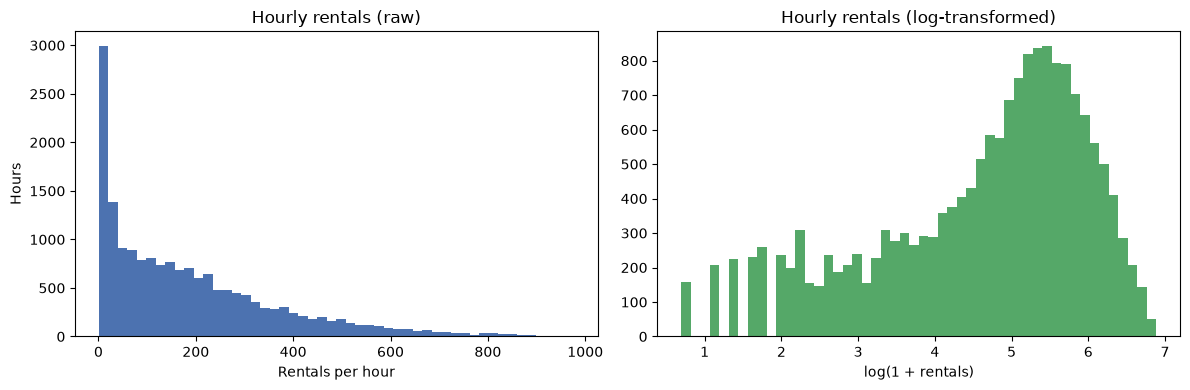

Skewness raw: 1.28 | log: -0.82


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(data["cnt"], bins=50, color="#4C72B0")
axes[0].set(title="Hourly rentals (raw)", xlabel="Rentals per hour", ylabel="Hours")
axes[1].hist(np.log1p(data["cnt"]), bins=50, color="#55A868")
axes[1].set(title="Hourly rentals (log-transformed)", xlabel="log(1 + rentals)")
plt.tight_layout(); plt.savefig("figures/01_target_distribution.png", dpi=150); plt.show()

print("Skewness raw:", round(data["cnt"].skew(), 2), "| log:", round(np.log1p(data["cnt"]).skew(), 2))

### 3.2 Hourly pattern — working days vs non-working days (headline chart)

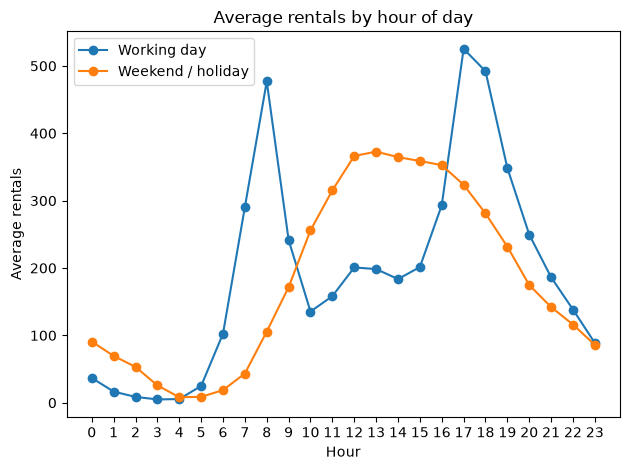

In [8]:
hourly = data.groupby(["hr", "workingday"])["cnt"].mean().unstack()
plt.plot(hourly.index, hourly[1], marker="o", label="Working day")
plt.plot(hourly.index, hourly[0], marker="o", label="Weekend / holiday")
plt.xticks(range(0, 24))
plt.title("Average rentals by hour of day"); plt.xlabel("Hour"); plt.ylabel("Average rentals")
plt.legend(); plt.tight_layout(); plt.savefig("figures/02_hourly_pattern.png", dpi=150); plt.show()

### 3.3 Temperature — is the relationship linear?

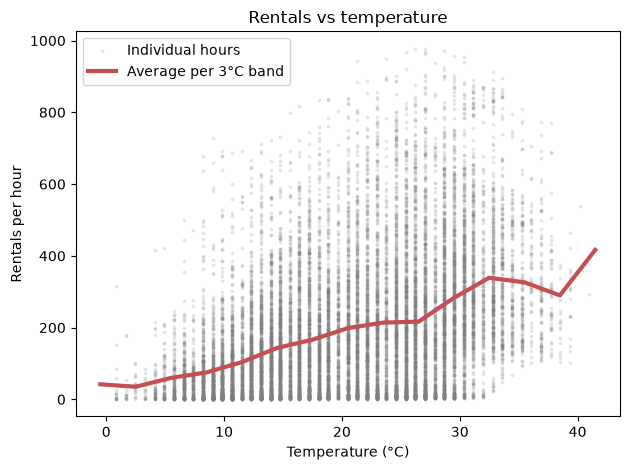

In [9]:
data["temp_band"] = pd.cut(data["temp_c"], bins=range(-5, 45, 3))
temp_curve = data.groupby("temp_band", observed=True)["cnt"].mean()

plt.scatter(data["temp_c"], data["cnt"], s=3, alpha=0.15, color="grey", label="Individual hours")
plt.plot([b.mid for b in temp_curve.index], temp_curve.values, color="#C44E52", lw=3, label="Average per 3°C band")
plt.title("Rentals vs temperature"); plt.xlabel("Temperature (°C)"); plt.ylabel("Rentals per hour")
plt.legend(); plt.tight_layout(); plt.savefig("figures/03_temperature.png", dpi=150); plt.show()

### 3.4 Weather

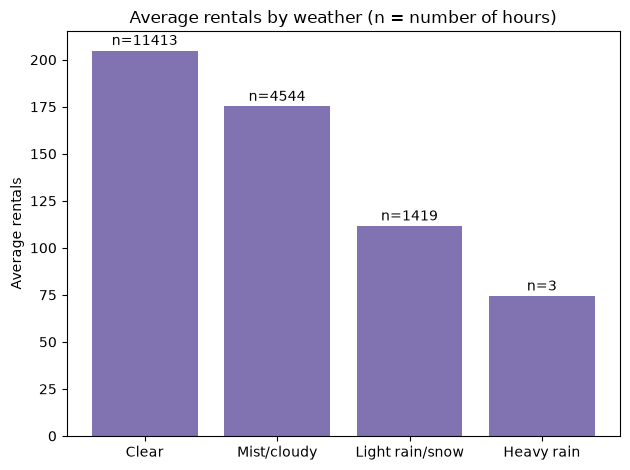

,mean,count
weather_name,,
Clear,204.869272,11413
Mist/cloudy,175.165493,4544
Light rain/snow,111.579281,1419
Heavy rain,74.333333,3


In [10]:
w = data.groupby("weather_name")["cnt"].agg(["mean", "count"]).reindex(list(weather_labels.values())).dropna()
plt.bar(w.index, w["mean"], color="#8172B2")
for i, (m, n) in enumerate(zip(w["mean"], w["count"])):
    plt.text(i, m + 3, f"n={int(n)}", ha="center")
plt.title("Average rentals by weather (n = number of hours)"); plt.ylabel("Average rentals")
plt.tight_layout(); plt.savefig("figures/04_weather.png", dpi=150); plt.show()
w

### 3.5 Trend over time — growth between 2011 and 2012

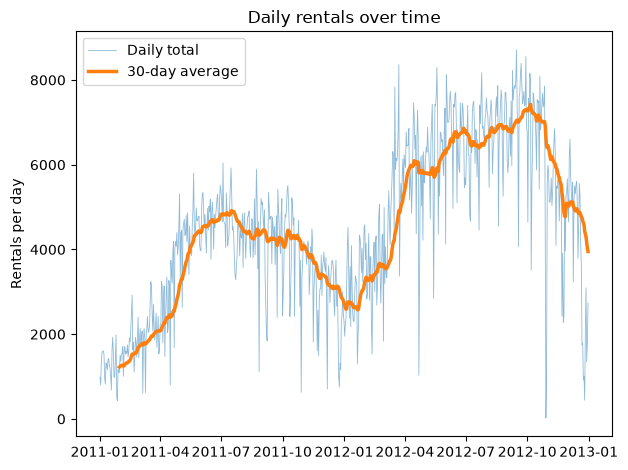

datetime
2011    143.794448
2012    234.666361
Name: avg rentals/hour, dtype: float64


In [11]:
daily = data.set_index("datetime")["cnt"].resample("D").sum()
plt.plot(daily.index, daily.values, lw=0.6, alpha=0.5, label="Daily total")
plt.plot(daily.rolling(30).mean(), lw=2.5, label="30-day average")
plt.title("Daily rentals over time"); plt.ylabel("Rentals per day"); plt.legend()
plt.tight_layout(); plt.savefig("figures/05_trend.png", dpi=150); plt.show()

print(data.groupby(data["datetime"].dt.year)["cnt"].mean().rename("avg rentals/hour"))

### 3.6 Correlations between numeric features

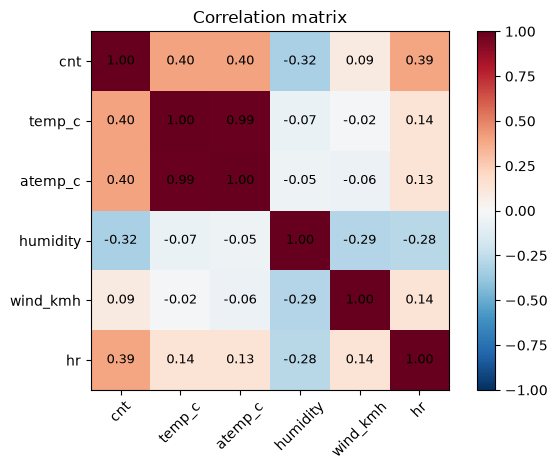

In [12]:
num_cols = ["cnt", "temp_c", "atemp_c", "humidity", "wind_kmh", "hr"]
corr = data[num_cols].corr()
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(); plt.xticks(range(len(num_cols)), num_cols, rotation=45); plt.yticks(range(len(num_cols)), num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.title("Correlation matrix"); plt.tight_layout(); plt.savefig("figures/06_correlation.png", dpi=150); plt.show()
# Note: temp and atemp are almost perfectly correlated -> keep only one (multicollinearity)

## 4. Feature engineering
- **Cyclical hour** (sin/cos) so the model knows 23:00 and 00:00 are neighbours.
- **Rush-hour flag** for commuter peaks on working days.
- **Hour × working day interaction.**
- **Temperature squared** to capture the "too hot" dip.
- **Log target**, converted back to real bike counts for evaluation.

In [13]:
fe = data.copy()
fe["hr_sin"] = np.sin(2 * np.pi * fe["hr"] / 24)
fe["hr_cos"] = np.cos(2 * np.pi * fe["hr"] / 24)
fe["rush_hour"] = (fe["workingday"].eq(1) & fe["hr"].isin([7, 8, 9, 16, 17, 18, 19])).astype(int)
fe["hr_x_workingday"] = fe["hr"] * fe["workingday"]
fe["temp_sq"] = fe["temp_c"] ** 2
fe["log_cnt"] = np.log1p(fe["cnt"])

# One-hot encode categorical features (they are categories, not quantities)
fe = pd.get_dummies(fe, columns=["weathersit", "season"], prefix=["weather", "season"], drop_first=True, dtype=int)

feature_cols = (
    ["hr", "hr_sin", "hr_cos", "rush_hour", "hr_x_workingday", "workingday", "holiday", "weekday",
     "temp_c", "temp_sq", "humidity", "wind_kmh", "yr", "mnth"]
    + [c for c in fe.columns if c.startswith(("weather_", "season_")) and c not in ("weather_name", "season_name")]
)
# atemp_c deliberately excluded: almost identical to temp_c (see correlation matrix)
print(len(feature_cols), "features:", feature_cols)

20 features: ['hr', 'hr_sin', 'hr_cos', 'rush_hour', 'hr_x_workingday', 'workingday', 'holiday', 'weekday', 'temp_c', 'temp_sq', 'humidity', 'wind_kmh', 'yr', 'mnth', 'weather_2', 'weather_3', 'weather_4', 'season_2', 'season_3', 'season_4']


## 5. Model implementation
**Validation:** time-based split — train on everything before 1 Oct 2012, test on the last 3 months.
A random split would let the model see hours right next to the test hours (near-identical), giving over-optimistic scores.

In [ ]:
split_date = pd.Timestamp("2012-10-01")
train, test = fe[fe["datetime"] < split_date], fe[fe["datetime"] >= split_date]
X_train, X_test = train[feature_cols], test[feature_cols]
y_train_log, y_test = train["log_cnt"], test["cnt"]
print(f"Train: {len(train)} hours ({train['datetime'].min():%d %b %Y} – {train['datetime'].max():%d %b %Y})")
print(f"Test:  {len(test)} hours ({test['datetime'].min():%d %b %Y} – {test['datetime'].max():%d %b %Y})")

In [ ]:
def evaluate(name, preds):
    return {"Model": name,
            "RMSE": mean_squared_error(y_test, preds) ** 0.5,
            "MAE": mean_absolute_error(y_test, preds),
            "R2": r2_score(y_test, preds)}

results, predictions = [], {}

# Baseline: average rentals for that hour + working-day combination in the training data
baseline_lookup = train.groupby(["hr", "workingday"])["cnt"].mean()
predictions["Baseline (hourly average)"] = test.set_index(["hr", "workingday"]).index.map(baseline_lookup).values

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=RANDOM_STATE),
}
for name, model in models.items():
    model.fit(X_train, y_train_log)
    predictions[name] = np.clip(np.expm1(model.predict(X_test)), 0, None)   # back to bike counts

for name, preds in predictions.items():
    results.append(evaluate(name, preds))

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

## 6. Model evaluation
### 6.1 Cross-validation on the training period (walk-forward)
Checks the scores are stable, not just lucky on one test period.

In [ ]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
tscv = TimeSeriesSplit(n_splits=5)
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train_log, cv=tscv, scoring="neg_root_mean_squared_error")
    print(f"{name:20s} RMSE on log scale: {-scores.mean():.3f} ± {scores.std():.3f}")

### 6.2 Predicted vs actual (one test week)

In [ ]:
best_name = results_df.drop(index="Baseline (hourly average)")["RMSE"].idxmin()
week = test["datetime"] < test["datetime"].min() + pd.Timedelta(days=7)
plt.plot(test.loc[week, "datetime"], y_test[week], label="Actual", lw=2, color="black")
plt.plot(test.loc[week, "datetime"], predictions[best_name][week.values], label=best_name, lw=2, ls="--")
plt.plot(test.loc[week, "datetime"], predictions["Linear Regression"][week.values], label="Linear Regression", alpha=0.6)
plt.title("Actual vs predicted rentals — first test week"); plt.ylabel("Rentals per hour"); plt.legend()
plt.tight_layout(); plt.savefig("figures/07_actual_vs_predicted.png", dpi=150); plt.show()

### 6.3 Where does the best model go wrong? (error by hour)

In [ ]:
err = pd.DataFrame({"hr": test["hr"].values, "abs_error": np.abs(y_test.values - predictions[best_name])})
err.groupby("hr")["abs_error"].mean().plot(kind="bar", color="#C44E52")
plt.title(f"{best_name}: average error by hour"); plt.xlabel("Hour"); plt.ylabel("Mean absolute error (bikes)")
plt.tight_layout(); plt.savefig("figures/08_error_by_hour.png", dpi=150); plt.show()

### 6.4 Feature importance (permutation importance on the test set)

In [ ]:
best_model = models[best_name]
perm = permutation_importance(best_model, X_test, np.log1p(y_test), n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=feature_cols).sort_values()
imp.tail(12).plot(kind="barh", color="#4C72B0")
plt.title(f"Most important features — {best_name}"); plt.xlabel("Drop in R² when feature is shuffled")
plt.tight_layout(); plt.savefig("figures/09_feature_importance.png", dpi=150); plt.show()

## 7. Notes for the Discussion section
Points to check against your own results:
- How much better is the best model than the hourly-average baseline? (That gap is what the ML actually adds.)
- Linear vs tree models: does the gap confirm the non-linear patterns seen in EDA (temperature curve, two peaks)?
- Which hours have the largest errors — the peaks? Why might that be?
- Limitations: recorded rentals ≠ true demand (empty stations), one city, two years, scheme growth (`yr`), very few heavy-rain hours.
- Future work: separate models for casual vs registered riders, events/holiday data, test on another city's data (e.g. London Santander Cycles via TfL open data).

In [ ]:
results_df.to_csv("figures/results_table.csv")
print(results_df.to_string())